In [31]:
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [32]:
import os

print(os.listdir("/content"))

['.config', 'models', 'aotizhongxin_features.csv', 'sample_data']


In [33]:
from google.colab import files
uploaded = files.upload()

Saving aotizhongxin_features.csv to aotizhongxin_features (1).csv


In [34]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


In [35]:
import os
print(os.path.exists("/content/aotizhongxin_features.csv"))

True


In [36]:
import pandas as pd

df = pd.read_csv("/content/aotizhongxin_features.csv")

df["datetime"] = pd.to_datetime(
    df[["year", "month", "day", "hour"]]
)

df = df.set_index("datetime")

print("Dataset loaded successfully:", df.shape)
display(df.head())

Dataset loaded successfully: (33878, 50)


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,...,wd_NNW,wd_NW,wd_S,wd_SE,wd_SSE,wd_SSW,wd_SW,wd_W,wd_WNW,wd_WSW
datetime,,,,,,,,,,,,,,,,,,,,,
2013-03-02 00:00:00,25,2013,3,2,0,22.0,24.0,24.0,44.0,500.0,...,False,False,False,False,False,False,False,False,False,False
2013-03-02 01:00:00,26,2013,3,2,1,14.0,17.0,21.0,36.0,400.0,...,False,False,False,False,False,False,False,False,False,False
2013-03-02 02:00:00,27,2013,3,2,2,13.0,13.0,20.0,37.0,400.0,...,False,False,False,False,False,False,False,False,False,False
2013-03-02 03:00:00,28,2013,3,2,3,3.0,9.0,13.0,34.0,400.0,...,False,False,False,False,False,False,False,False,False,False
2013-03-02 04:00:00,29,2013,3,2,4,3.0,7.0,18.0,43.0,400.0,...,True,False,False,False,False,False,False,False,False,False


In [37]:
# Split x and y
TARGET = "PM2.5"

X = df.drop(columns=[TARGET]).values
y = df[TARGET].values.reshape(-1, 1)

In [38]:
print("X shape:", X.shape)
print("X type:", type(X))

X shape: (33878, 49)
X type: <class 'numpy.ndarray'>


In [39]:
print(df.columns.tolist())

['No', 'year', 'month', 'day', 'hour', 'PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM', 'station', 'PM2.5_lag_1h', 'PM2.5_lag_3h', 'PM2.5_lag_6h', 'PM2.5_lag_12h', 'PM2.5_lag_24h', 'PM2.5_roll_mean_3h', 'PM2.5_roll_std_3h', 'PM2.5_roll_mean_6h', 'PM2.5_roll_std_6h', 'PM2.5_roll_mean_12h', 'PM2.5_roll_std_12h', 'PM2.5_roll_mean_24h', 'PM2.5_roll_std_24h', 'dayofweek', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'wd_ENE', 'wd_ESE', 'wd_N', 'wd_NE', 'wd_NNE', 'wd_NNW', 'wd_NW', 'wd_S', 'wd_SE', 'wd_SSE', 'wd_SSW', 'wd_SW', 'wd_W', 'wd_WNW', 'wd_WSW']


In [40]:
# Remove non-numeric station column
df = df.drop(columns=["station"])

# Prepare features and target
X = df.drop(columns=["PM2.5"]).values
y = df[["PM2.5"]].values

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (33878, 48)
y shape: (33878, 1)


In [41]:
import numpy as np
from sklearn.preprocessing import StandardScaler

# Convert data into NumPy arrays
X = np.asarray(X)
y = np.asarray(y).reshape(-1, 1)

# Chronological train-validation-test split (70/15/15)
n = len(X)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

X_train = X[:train_end]
X_val = X[train_end:val_end]
X_test = X[val_end:]

y_train = y[:train_end]
y_val = y[train_end:val_end]
y_test = y[val_end:]

# Initialize scalers
scaler_X = StandardScaler()
scaler_y = StandardScaler()

# Fit ONLY on training data
X_train_scaled = scaler_X.fit_transform(X_train)
y_train_scaled = scaler_y.fit_transform(y_train)

# Transform validation and test data without fitting again
X_val_scaled = scaler_X.transform(X_val)
X_test_scaled = scaler_X.transform(X_test)

y_val_scaled = scaler_y.transform(y_val)
y_test_scaled = scaler_y.transform(y_test)

print("Scaling completed without data leakage!")
print("Training:", X_train_scaled.shape, y_train_scaled.shape)
print("Validation:", X_val_scaled.shape, y_val_scaled.shape)
print("Testing:", X_test_scaled.shape, y_test_scaled.shape)

Scaling completed without data leakage!
Training: (23714, 48) (23714, 1)
Validation: (5082, 48) (5082, 1)
Testing: (5082, 48) (5082, 1)


In [42]:
import numpy as np

# Sequence creation function
def create_sequences(X, y, seq_len=24):
    Xs, ys = [], []

    for i in range(seq_len, len(X)):
        Xs.append(X[i-seq_len:i])
        ys.append(y[i])

    return np.array(Xs), np.array(ys)


SEQ_LEN = 24

# Create sequences separately for each split
X_train_seq, y_train_seq = create_sequences(
    X_train_scaled, y_train_scaled, SEQ_LEN
)

X_val_seq, y_val_seq = create_sequences(
    X_val_scaled, y_val_scaled, SEQ_LEN
)

X_test_seq, y_test_seq = create_sequences(
    X_test_scaled, y_test_scaled, SEQ_LEN
)

print("Sequence generation completed!")
print("Training:", X_train_seq.shape, y_train_seq.shape)
print("Validation:", X_val_seq.shape, y_val_seq.shape)
print("Testing:", X_test_seq.shape, y_test_seq.shape)

Sequence generation completed!
Training: (23690, 24, 48) (23690, 1)
Validation: (5058, 24, 48) (5058, 1)
Testing: (5058, 24, 48) (5058, 1)


In [43]:
# Use already generated train, validation and test sequences

X_train = X_train_seq
y_train = y_train_seq

X_val = X_val_seq
y_val = y_val_seq

X_test = X_test_seq
y_test = y_test_seq

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (23690, 24, 48) (23690, 1)
Validation: (5058, 24, 48) (5058, 1)
Test: (5058, 24, 48) (5058, 1)


In [44]:
import torch

X_train_tensor = torch.tensor(X_train_seq, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_seq, dtype=torch.float32)

X_val_tensor = torch.tensor(X_val_seq, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val_seq, dtype=torch.float32)

X_test_tensor = torch.tensor(X_test_seq, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test_seq, dtype=torch.float32)

print("All LSTM tensors created successfully!")

All LSTM tensors created successfully!


In [45]:
class LSTMModel(nn.Module):
    def __init__(self, input_size, hidden_size=64):
        super().__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, batch_first=True)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        _, (h_n, _) = self.lstm(x)
        out = self.fc(h_n[-1])
        return out

In [46]:
model = LSTMModel(input_size=X_train.shape[2]).to(device)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [47]:
# Dataloaders
BATCH_SIZE = 15
EPOCHS = 30

train_loader = DataLoader(
    TensorDataset(X_train_t, y_train_t),
    batch_size=BATCH_SIZE,
    shuffle=False
)

val_loader = DataLoader(
    TensorDataset(X_val_t, y_val_t),
    batch_size=BATCH_SIZE,
    shuffle=False
)

In [48]:
# Training
from tqdm import tqdm

train_losses = []
val_losses = []

for epoch in range(EPOCHS):
    model.train()
    train_loss = 0.0

    train_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{EPOCHS} [Training]",
        leave=False
    )

    for xb, yb in train_bar:
        optimizer.zero_grad()

        preds = model(xb)
        loss = criterion(preds, yb)

        loss.backward()
        optimizer.step()

        train_loss += loss.item()
        train_bar.set_postfix(batch_loss=loss.item())

    # Validation
    model.eval()
    val_loss = 0.0

    with torch.no_grad():
        for xb, yb in val_loader:
            preds = model(xb)
            loss = criterion(preds, yb)
            val_loss += loss.item()

    # Epoch metrics
    train_epoch_loss = train_loss / len(train_loader)
    val_epoch_loss = val_loss / len(val_loader)

    train_losses.append(train_epoch_loss)
    val_losses.append(val_epoch_loss)

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train MSE: {train_epoch_loss:.4f} | "
        f"Val MSE: {val_epoch_loss:.4f}"
    )

Epoch 1/30 | Train MSE: 0.1600 | Val MSE: 0.0988


Epoch 2/30 | Train MSE: 0.0862 | Val MSE: 0.0836


Epoch 3/30 | Train MSE: 0.0754 | Val MSE: 0.0844


Epoch 4/30 | Train MSE: 0.0697 | Val MSE: 0.0803


Epoch 5/30 | Train MSE: 0.0639 | Val MSE: 0.0817


Epoch 6/30 | Train MSE: 0.0596 | Val MSE: 0.0790


... (20 outputs left out)

Epoch 27/30 | Train MSE: 0.0225 | Val MSE: 0.0994


Epoch 28/30 | Train MSE: 0.0227 | Val MSE: 0.1048


Epoch 29/30 | Train MSE: 0.0224 | Val MSE: 0.1017


Epoch 30/30 | Train MSE: 0.0206 | Val MSE: 0.1064


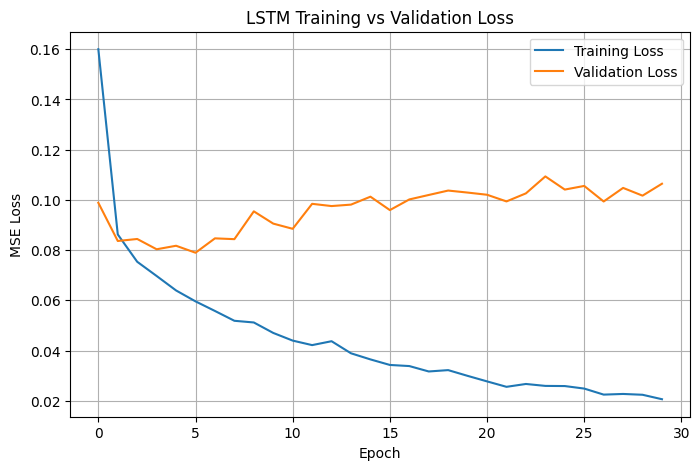

In [49]:
import matplotlib.pyplot as plt

# Graph for training vs validation loss
plt.figure(figsize=(8, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("LSTM Training vs Validation Loss")
plt.legend()
plt.grid(True)

plt.show()

In [50]:
model.eval()
with torch.no_grad():
    y_test_pred = model(X_test_t).cpu().numpy()

# Inverse scaling
y_test_inv = scaler_y.inverse_transform(y_test)
y_pred_inv = scaler_y.inverse_transform(y_test_pred)

mae = mean_absolute_error(y_test_inv, y_pred_inv)
rmse = np.sqrt(mean_squared_error(y_test_inv, y_pred_inv))
r2 = r2_score(y_test_inv, y_pred_inv)

print("LSTM Test Performance:")
print(f"MAE : {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²  : {r2:.3f}")

LSTM Test Performance:
MAE : 17.30
RMSE: 26.42
R²  : 0.921


In [51]:
from pathlib import Path

MODEL_DIR = Path("/content/models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

torch.save(model.state_dict(), MODEL_DIR / "lstm_pm25_pytorch.pt")

print("LSTM model saved successfully!")

LSTM model saved successfully!


In [52]:
from google.colab import files
files.download("/content/models/lstm_pm25_pytorch.pt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>